In [11]:
import time; T0 = time.time()
import numpy as np, matplotlib.pyplot as plt
from scipy import stats
from mp2lib import (inv_cdf_exponential, inv_cdf_rayleigh, sample_by_inversion,
                    ks_statistic, q_function)

SEED = 981253769
rng = np.random.default_rng(SEED)
# one independent generator per step, created once
rng_step = {k: g for k, g in zip(range(1, 9), rng.spawn(8))}
N = 10**5
KS_CRIT = 1.36 / np.sqrt(N)
print(f"N = {N}, 95% KS critical value = {KS_CRIT:.4f}")

N = 100000, 95% KS critical value = 0.0043


## Step 1: From CDF to Density

**The Four Distributions**

| Distribution | Support | CDF $F(x)$ | pdf $f(x)$ |
|---|---|---|---|
| Uniform on $[0,1]$ | $[0,1]$ | $x$ | $1$ |
| Exponential, rate 1 | $[0,\infty)$ | $1-e^{-x}$ | $e^{-x}$ |
| Standard Gaussian | $(-\infty,\infty)$ | $\Phi(x)=\tfrac12\left[1+\operatorname{erf}\left(x/\sqrt2\right)\right]$ | $\tfrac{1}{\sqrt{2\pi}}\,e^{-x^2/2}$ |
| Rayleigh, scale 1 | $[0,\infty)$ | $1-e^{-x^2/2}$ | $x\,e^{-x^2/2}$ |

Outside its support, each pdf is 0 and each CDF is 0 to the left and 1 to the right.

**Closed Forms**

| | Mean | Median | Variance |
|---|---|---|---|
| Exponential, rate $\lambda$ | $\dfrac{1}{\lambda}$ | $\dfrac{\ln 2}{\lambda}$ | $\dfrac{1}{\lambda^{2}}$ |
| Rayleigh, scale $\sigma$ | $\sigma\sqrt{\dfrac{\pi}{2}}$ | $\sigma\sqrt{2\ln 2}$ | $\dfrac{4-\pi}{2}\,\sigma^{2}$ |

With $\lambda=\sigma=1$:

- Exponential: mean $1$, median $0.6931$, variance $1$.
- Rayleigh: mean $1.2533$, median $1.1774$, variance $0.4292$.

**Explanation**

The exponential density is skewed to the right: its long tail carries rare, large values that pull the mean up to 1, while the median only marks the point with half the probability on each side and stays at $\ln 2\approx0.693$, a ratio of about 1.44. The Gaussian density is symmetric about its center, so the point that splits the probability in half is also the balance point, and the mean and median coincide.

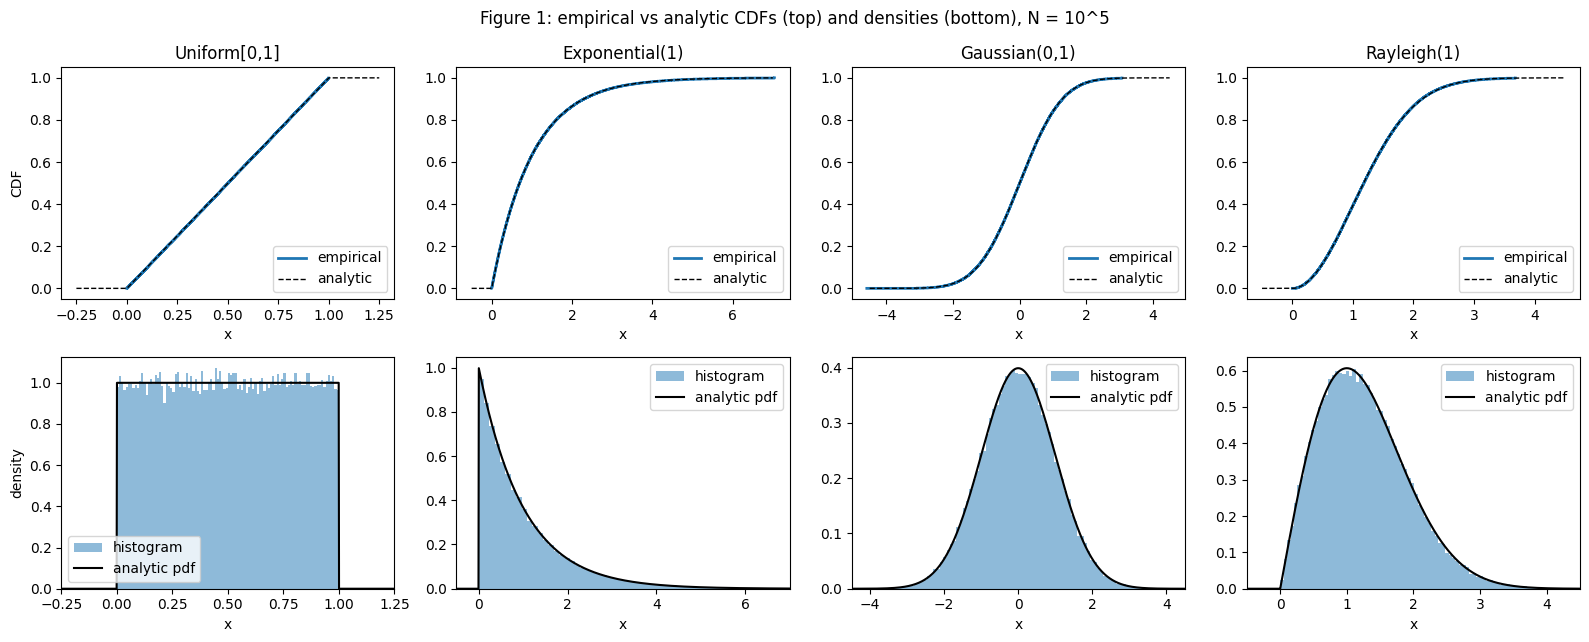

distribution      KS statistic  95% crit   verdict
Uniform[0,1]           0.00228    0.0043   pass
Exponential(1)         0.00205    0.0043   pass
Gaussian(0,1)          0.00237    0.0043   pass
Rayleigh(1)            0.00260    0.0043   pass
                              sample  closed form
Exponential(1)  mean          1.0017       1.0000
Exponential(1)  median        0.6932       0.6931
Exponential(1)  variance      1.0146       1.0000
Rayleigh(1)     mean          1.2525       1.2533
Rayleigh(1)     median        1.1808       1.1774
Rayleigh(1)     variance      0.4283       0.4292


In [ ]:
# STEP 1 - From CDF to Density

# Figure 1. Empirical vs Analytic CDF Figures and Histograms
r1 = rng_step[1]
dists = {
 "Uniform[0,1]": dict(draw=lambda n: r1.random(n),            cdf=lambda x: np.clip(x,0,1),
                      pdf=lambda x: ((x>=0)&(x<=1)).astype(float), xs=(-0.25,1.25)),
 "Exponential(1)": dict(draw=lambda n: r1.exponential(1.0, n), cdf=lambda x: np.where(x>0,1-np.exp(-np.maximum(x,0)),0.0),
                      pdf=lambda x: np.where(x>=0,np.exp(-np.maximum(x,0)),0.0), xs=(-0.5,7)),
 "Gaussian(0,1)": dict(draw=lambda n: r1.standard_normal(n), cdf=stats.norm.cdf,
                      pdf=stats.norm.pdf, xs=(-4.5,4.5)),
 "Rayleigh(1)": dict(draw=lambda n: r1.rayleigh(1.0, n),     cdf=lambda x: np.where(x>0,1-np.exp(-np.maximum(x,0)**2/2),0.0),
                      pdf=lambda x: np.where(x>=0,x*np.exp(-x**2/2),0.0), xs=(-0.5,4.5)),
}
samples = {k: d["draw"](N) for k, d in dists.items()}
 
fig, ax = plt.subplots(2, 4, figsize=(16, 6.5))
for j, (k, d) in enumerate(dists.items()):
    s = np.sort(samples[k]); x = np.linspace(*d["xs"], 1000)
    ax[0,j].step(s[::100], np.arange(1, N+1)[::100]/N, where="post", color="C0", lw=2, label="empirical")
    ax[0,j].plot(x, d["cdf"](x), "k--", lw=1, label="analytic")
    ax[0,j].set_title(k); ax[0,j].set_xlabel("x"); ax[0,j].legend(loc="lower right")
    ax[1,j].hist(samples[k], bins=100, density=True, color="C0", alpha=.5, label="histogram")
    ax[1,j].plot(x, d["pdf"](x), "k", lw=1.5, label="analytic pdf")
    ax[1,j].set_xlim(*d["xs"]); ax[1,j].set_xlabel("x"); ax[1,j].legend()
ax[0,0].set_ylabel("CDF"); ax[1,0].set_ylabel("density")
fig.suptitle("Figure 1: empirical vs analytic CDFs (top) and densities (bottom), N = 10^5")
fig.tight_layout(); plt.show()
 
# KS statistic table
print(f"{'distribution':<16}{'KS statistic':>14}{'95% crit':>10}   verdict")
for k, d in dists.items():
    ks = ks_statistic(samples[k], d["cdf"])
    print(f"{k:<16}{ks:>14.5f}{KS_CRIT:>10.4f}   {'pass' if ks < KS_CRIT else 'FAIL'}")
 
# Sample mean, median, variance vs closed form
closed = {"Exponential(1)": (1.0, np.log(2), 1.0),
          "Rayleigh(1)":    (np.sqrt(np.pi/2), np.sqrt(2*np.log(2)), (4-np.pi)/2)}
print(f"{'':<16}{'':<10}{'sample':>10}{'closed form':>13}")
for k, (m, med, v) in closed.items():
    s = samples[k]
    for name, emp, th in [("mean", s.mean(), m), ("median", np.median(s), med), ("variance", s.var(ddof=1), v)]:
        print(f"{k:<16}{name:<10}{emp:>10.4f}{th:>13.4f}")

## Step 2: Build Your Own Generator by Inversion

**Inversion theorem.** Let $U$ be uniform on $[0,1]$, and let $F$ be a continuous, strictly increasing CDF with inverse $F^{-1}$. Then $X=F^{-1}(U)$ has CDF $F$.

*Proof.* Because $F$ is strictly increasing, $F^{-1}(U)\le x$ holds exactly when $U\le F(x)$. Therefore
$$P[X\le x]=P[U\le F(x)]=F(x),$$
since $P[U\le t]=t$ for every $t\in[0,1]$ and $F(x)\in[0,1]$.

**Deriving $F^{-1}$ by hand**

*Exponential with rate $\lambda$.* The CDF is $F(x)=1-e^{-\lambda x}$ for $x\ge0$. Set $u=F(x)$ and solve for $x$:
$$u=1-e^{-\lambda x}\;\Rightarrow\;e^{-\lambda x}=1-u\;\Rightarrow\;-\lambda x=\ln(1-u)\;\Rightarrow\;x=-\frac{\ln(1-u)}{\lambda}.$$
So $F^{-1}(u)=-\ln(1-u)/\lambda$.

*Rayleigh with scale $\sigma$.* The CDF is $F(x)=1-e^{-x^{2}/(2\sigma^{2})}$ for $x\ge0$. Set $u=F(x)$ and solve for $x$:
$$u=1-e^{-x^{2}/(2\sigma^{2})}\;\Rightarrow\;e^{-x^{2}/(2\sigma^{2})}=1-u\;\Rightarrow\;x^{2}=-2\sigma^{2}\ln(1-u)\;\Rightarrow\;x=\sigma\sqrt{-2\ln(1-u)}.$$
The support is $x\ge0$, so we keep the positive root. So $F^{-1}(u)=\sigma\sqrt{-2\ln(1-u)}$.

**The edge case $u=0$**

`rng.random()` returns values in $[0,1)$, so it can return exactly $0$ but never exactly $1$. Both inverse CDFs are written with $\ln(1-u)$, computed as `np.log1p(-u)`. At $u=0$ this gives $\ln 1=0$, so the sample is exactly $0$, which lies in the support. Since $1-u\in(0,1]$, the logarithm never receives $0$ and never returns $-\infty$, so no sample is infinite. The form $-\ln(u)$ would return $+\infty$ at $u=0$.

**Choice of formula.** If $U$ is uniform on $[0,1]$, then $1-U$ is also uniform on $[0,1]$, so $-\ln(1-U)/\lambda$ and $-\ln(U)/\lambda$ have the same distribution. I used $-\ln(1-U)/\lambda$, because it is the literal $F^{-1}$ and it is safe at $U=0$.

              KS vs analytic    crit   KS vs library  crit(2-sample)
Exponential          0.00160  0.0043         0.00444          0.0061
Rayleigh             0.00285  0.0043         0.00410          0.0061

min of inversion samples: 3.966951289759319e-06 0.0067971271723773355 | any inf/nan: False
u=0 handled: 0.0 0.0


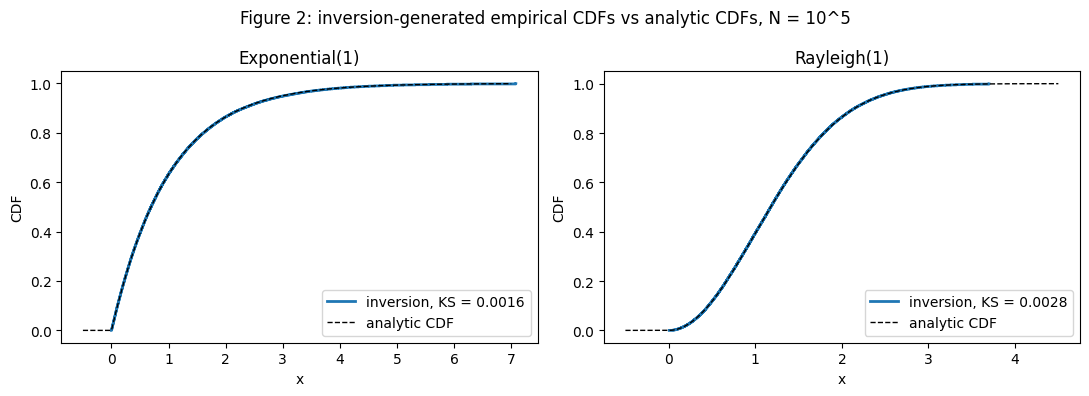

runtime so far: 2.2 s


In [13]:
# STEP 2 - Build Your Own Generator by Inversion

# Analytic CDFs
cdf_exp = lambda x: np.where(x > 0, 1 - np.exp(-np.maximum(x, 0)), 0.0)
cdf_ray = lambda x: np.where(x > 0, 1 - np.exp(-np.maximum(x, 0)**2 / 2), 0.0)
 
# Inversion samples and KS checks (analytic and library)
r2 = rng_step[2]
x_exp = sample_by_inversion(inv_cdf_exponential, N, r2, lam=1.0)
x_ray = sample_by_inversion(inv_cdf_rayleigh,    N, r2, sigma=1.0)
 
lib = np.random.default_rng(SEED + 1)
l_exp, l_ray = lib.exponential(1.0, N), lib.rayleigh(1.0, N)
 
ks_exp, ks_ray = ks_statistic(x_exp, cdf_exp), ks_statistic(x_ray, cdf_ray)
crit2 = 1.36 * np.sqrt(2 / N)
print(f"{'':<12}{'KS vs analytic':>16}{'crit':>8}{'KS vs library':>16}{'crit(2-sample)':>16}")
for name, x, l, ks in [("Exponential", x_exp, l_exp, ks_exp), ("Rayleigh", x_ray, l_ray, ks_ray)]:
    k2 = stats.ks_2samp(x, l).statistic
    print(f"{name:<12}{ks:>16.5f}{KS_CRIT:>8.4f}{k2:>16.5f}{crit2:>16.4f}")
 
print("\nmin of inversion samples:", x_exp.min(), x_ray.min(), "| any inf/nan:",
      not np.isfinite(np.concatenate([x_exp, x_ray])).all())
print("u=0 handled:", inv_cdf_exponential(0.0, 1.0), inv_cdf_rayleigh(0.0, 1.0))
 
# Figure 2: inversion CDFs vs analytic CDFs
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, x, cdf, ks, name, xs in [(ax[0], x_exp, cdf_exp, ks_exp, "Exponential(1)", (-0.5, 7)),
                                (ax[1], x_ray, cdf_ray, ks_ray, "Rayleigh(1)", (-0.5, 4.5))]:
    s = np.sort(x); xx = np.linspace(*xs, 1000)
    a.step(s[::100], np.arange(1, N+1)[::100]/N, where="post", color="C0", lw=2, label=f"inversion, KS = {ks:.4f}")
    a.plot(xx, cdf(xx), "k--", lw=1, label="analytic CDF")
    a.set_title(name); a.set_xlabel("x"); a.set_ylabel("CDF"); a.legend(loc="lower right")
fig.suptitle("Figure 2: inversion-generated empirical CDFs vs analytic CDFs, N = 10^5")
fig.tight_layout(); plt.show()
print(f"runtime so far: {time.time()-T0:.1f} s")